# Correlation, blocking and replicas

Original educational notebook. Read the linked course chapters. All synthetic models are labeled; no material property is inferred from a short run.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'scripts/numerics.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Extract the complete repository, then open this notebook from its root or notebooks folder.')
sys.path.insert(0, str(ROOT))
np.set_printoptions(precision=5)


## Known correlated process
An AR(1) process with φ=0.9 has analytical statistical inefficiency g=19. It is synthetic time-series data, not a molecular trajectory.

Estimated g / analytical g: 19.297890620367724 19.000000000000004
Naive SE / correlation-adjusted SE: 0.009577659315734679 0.04207404867739465


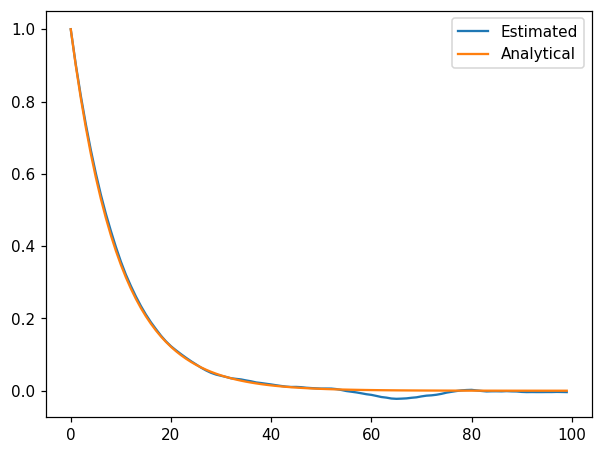

In [2]:
from scripts.numerics import autocorrelation,statistical_inefficiency,block_summary
rng=np.random.default_rng(23);phi=.9;x=np.zeros(60000)
for i in range(1,len(x)):x[i]=phi*x[i-1]+rng.normal()
x=x[1000:]
g=statistical_inefficiency(x)
print('Estimated g / analytical g:',g,(1+phi)/(1-phi))
print('Naive SE / correlation-adjusted SE:',x.std(ddof=1)/np.sqrt(len(x)),x.std(ddof=1)*np.sqrt(g/len(x)))
plt.plot(autocorrelation(x)[:100],label='Estimated')
plt.plot(phi**np.arange(100),label='Analytical');plt.legend();plt.show()

{'mean': -0.08244643174226804, 'se': 0.039921510545759306, 'ci_low': -0.16150889143843117, 'ci_high': -0.0033839720461048967, 'blocks': 118, 'block_size': 500, 'discarded_tail': 0, 'confidence': 0.95}


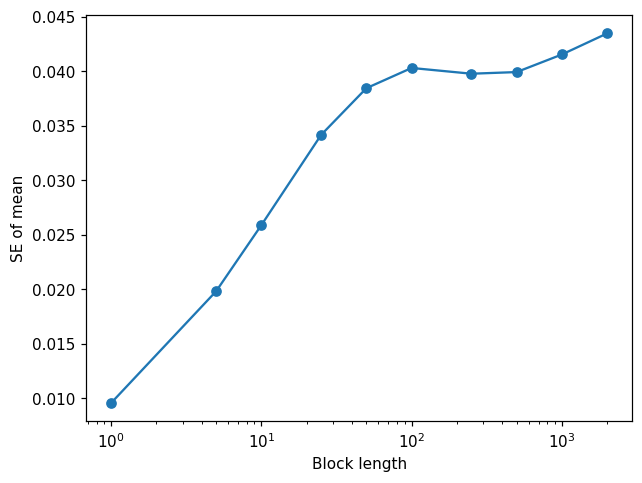

In [3]:
sizes=[1,5,10,25,50,100,250,500,1000,2000]
summaries=[block_summary(x,b) for b in sizes]
plt.semilogx(sizes,[s['se'] for s in summaries],'o-')
plt.xlabel('Block length');plt.ylabel('SE of mean');plt.show()
print(block_summary(x,500))

**Exercise:** add a slow drift or splice two different means. Explain why applying the same stationary-series formula then gives a misleading interval. Repeat independent seeds to assess interval coverage; a single correct-looking interval is not a coverage test.